# <center><span style="color:red"><u><br/> Analyses descriptives</u></span></center>

## <span style="color:RED">1-Introduction</span>

L'objectif de ce notebook est d'effectuer une analyse descriptive détaillée afin de comprendre la distribution de la valeur marchande des joueurs de Premier League lors de la saison 2025-2026 et d'identifier ses relations avec les caractéristiques des joueurs.

Pour cela, nous allons inclure des statistiques descriptives, des représentations graphiques et étudier les corrélations.

## <span style="color:red">2-Importation des bibliothèques</span>

In [49]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## <span style="color:red">3-Importation des données</span>

Nous utilisons les données 'dataset_final.csv' qui sont la fusion nettoyée de nos deux sources de données obtenue via le notebook 02_merging_and_cleaning qui se trouve dans le fichier data/processed.

In [33]:
df_stat_premier_league=pd.read_csv("../data/processed/dataset_final.csv")

## <span style="color:red">4-Analyses exploratoires</span>

On rappelle d'abord quelques éléments nécessaires pour bien comprendre les données que nous avons à disposition.

### <span style="color:red">Dictionnaire des variables</span>

In [34]:
df_stat_premier_league.info()

<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 25 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   id_fbref                              505 non-null    str    
 1   joueur                                505 non-null    str    
 2   poste                                 505 non-null    str    
 3   age                                   505 non-null    int64  
 4   annee_naissance                       505 non-null    int64  
 5   matchs_joues                          505 non-null    int64  
 6   titularisations                       505 non-null    int64  
 7   minutes_jouees                        505 non-null    int64  
 8   buts                                  505 non-null    int64  
 9   passes_decisives                      505 non-null    int64  
 10  buts_plus_passes                      505 non-null    int64  
 11  buts_hors_penalty             

#### <span style="color:red">Notes sur les variables</span>

**id_fbref** : Identifiant unique pour chaque joueur

**joueur** : Prénom et nom du joueur

**poste** : Position sur le terrain du joueur
GK (Goalkeeper) = Gardien de but
FW (Forward) = Attaquant
MF (Midfielder) = Milieu de terrain
DF (Defender) = Défenseur
Si un joueur a le poste FWMF, cela signifie qu'il peut jouer à la fois comme attaquant et comme milieu de terrain.

**age** : Âge du joueur lors de la saison 2025-2026

**matchs_joues** : Matchs joués lors de la saison 2025-2026

**titularisations** : Matchs démarrés en tant que titulaire lors de la saison 2025-2026

**minutes_jouees** : Minutes jouées lors de la saison 2025-2026

**buts** : Nombre de buts marqués lors de la saison 2025-2026

**passes_decisives** : Nombre de passes décisives réalisées lors de la saison 2025-2026

**buts_plus_passes** : Somme des buts et des passes décisives lors de la saison 2025-2026

**buts_hors_penalty** : Nombre de buts marqués hors penalty lors de la saison 2025-2026

**penaltys_marques** : Nombre de penaltys marqués lors de la saison 2025-2026

**penaltys_tentes** : Nombre de penaltys tentés lors de la saison 2025-2026

**cartons_jaunes** : Nombre de cartons jaunes reçus lors de la saison 2025-2026

**cartons_rouges** : Nombre de cartons rouges reçus lors de la saison 2025-2026

**equivalent_90_minutes** : Nombre de matchs équivalents à 90 minutes joués lors de la saison 2025-2026 (minutes jouées / 90)

**buts_par_90** : Nombre moyen de buts marqués par 90 minutes jouées

**passes_decisives_par_90** : Nombre moyen de passes décisives réalisées par 90 minutes jouées

**buts_plus_passes_par_90** : Nombre moyen de buts et passes décisives par 90 minutes jouées

**buts_hors_penalty_par_90** : Nombre moyen de buts marqués hors penalty par 90 minutes jouées

**buts_plus_passes_hors_penalty_par_90** : Nombre moyen de buts hors penalty et passes décisives par 90 minutes jouées

**nationalite** : Nationalité du joueur

**valeur_marchande** : Valeur marchande estimée du joueur

**log_valeur_marchande** : Logarithme de la valeur marchande du joueur

### <span style="color:red">Description des données</span>

In [35]:
df_stat_premier_league.head()

,id_fbref,joueur,poste,age,annee_naissance,matchs_joues,titularisations,minutes_jouees,buts,passes_decisives,...,cartons_rouges,equivalent_90_minutes,buts_par_90,passes_decisives_par_90,buts_plus_passes_par_90,buts_hors_penalty_par_90,buts_plus_passes_hors_penalty_par_90,nationalite,valeur_marchande,log_valeur_marchande
0,0041f3e6,Mohamadou Kanté,MF,19,2005,11,0,75,0,0,...,0,0.833333,0.000000,0.0,0.000000,0.000000,0.000000,France,1000000,13.815511
1,00963611,Konstantinos Mavropanos,DF,27,1997,31,27,2534,3,0,...,0,28.155556,0.106551,0.0,0.106551,0.106551,0.106551,Greece,18000000,16.705882
2,0107757e,Filip Jørgensen,GK,23,2002,5,3,379,0,0,...,0,4.211111,0.000000,0.0,0.000000,0.000000,0.000000,Denmark,15000000,16.523561
3,013d348e,Melker Ellborg,GK,22,2003,3,3,270,0,0,...,0,3.000000,0.000000,0.0,0.000000,0.000000,0.000000,Sweden,3000000,14.914123
4,01834aa0,Sebastiaan Bornauw,DF,26,1999,12,5,429,0,0,...,0,4.766667,0.000000,0.0,0.000000,0.000000,0.000000,Belgium,8000000,15.894952


In [36]:
df_stat_premier_league.info()

<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 25 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   id_fbref                              505 non-null    str    
 1   joueur                                505 non-null    str    
 2   poste                                 505 non-null    str    
 3   age                                   505 non-null    int64  
 4   annee_naissance                       505 non-null    int64  
 5   matchs_joues                          505 non-null    int64  
 6   titularisations                       505 non-null    int64  
 7   minutes_jouees                        505 non-null    int64  
 8   buts                                  505 non-null    int64  
 9   passes_decisives                      505 non-null    int64  
 10  buts_plus_passes                      505 non-null    int64  
 11  buts_hors_penalty             

#### <span style="color:red">Valeurs manquantes</span>
Aucune valeur n'est manquante, cela s'explique par le fait qu'on avait traité cela avant de fusionner nos tables dans le notebook 02_merging_and_cleaning.

#### <span style="color:red">Type des variables</span>

- **Variables catégorielles** : poste, nationalite
- **Variables numériques** : age, annee_naissance, matchs_joues, titularisations, minutes_jouees, buts, passes_decisives, buts_plus_passes, buts_hors_penalty, penaltys_marques, penaltys_tentes, cartons_jaunes, cartons_rouges, equivalent_90_minutes, buts_par_90, passes_decisives_par_90, buts_plus_passes_par_90, buts_hors_penalty_par_90, buts_plus_passes_hors_penalty_par_90, valeur_marchande, log_valeur_marchande
- **Variables textuelles** : id_fbref, joueur

### <span style="color:red">Statistiques univariées</span>

Avant toute chose, il est important de visualiser les distributions des différentes variables que nous avons à notre disposition.

#### <span style="color:red">Variables numériques</span>

In [37]:
num_var=['age','annee_naissance','matchs_joues','titularisations','minutes_jouees','buts','passes_decisives', 'buts_plus_passes','buts_hors_penalty','penaltys_marques','penaltys_tentes','cartons_jaunes','cartons_rouges', 'equivalent_90_minutes','buts_par_90','passes_decisives_par_90','buts_plus_passes_par_90','buts_hors_penalty_par_90', 'buts_plus_passes_hors_penalty_par_90','valeur_marchande','log_valeur_marchande']

df_stat_premier_league[num_var].describe()

,age,annee_naissance,matchs_joues,titularisations,minutes_jouees,buts,passes_decisives,buts_plus_passes,buts_hors_penalty,penaltys_marques,...,cartons_jaunes,cartons_rouges,equivalent_90_minutes,buts_par_90,passes_decisives_par_90,buts_plus_passes_par_90,buts_hors_penalty_par_90,buts_plus_passes_hors_penalty_par_90,valeur_marchande,log_valeur_marchande
count,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,...,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,5.050000e+02,505.000000
mean,24.956436,1999.651485,21.586139,15.740594,1415.108911,1.908911,1.320792,3.229703,1.762376,0.146535,...,2.693069,0.081188,15.723432,0.118954,0.077788,0.196742,0.112052,0.189840,2.382317e+07,16.427172
std,4.292630,4.322482,11.770668,11.955026,1032.406407,3.239700,1.957906,4.462666,2.895496,0.677232,...,2.804979,0.287543,11.471182,0.325833,0.118556,0.352787,0.321998,0.348960,2.281839e+07,1.288567
min,15.000000,1986.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.011111,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000e+05,11.512925
25%,22.000000,1997.000000,12.000000,5.000000,459.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,5.100000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000e+06,15.894952
50%,25.000000,2000.000000,24.000000,15.000000,1336.000000,1.000000,1.000000,1.000000,1.000000,0.000000,...,2.000000,0.000000,14.844444,0.031836,0.032823,0.114601,0.030992,0.114117,1.800000e+07,16.705882
75%,28.000000,2003.000000,32.000000,26.000000,2222.000000,2.000000,2.000000,5.000000,2.000000,0.000000,...,4.000000,0.000000,24.688889,0.146659,0.115570,0.293399,0.136917,0.279938,3.000000e+07,17.216708
max,39.000000,2009.000000,38.000000,38.000000,3420.000000,27.000000,21.000000,35.000000,24.000000,8.000000,...,12.000000,2.000000,38.000000,6.428571,0.978261,6.428571,6.428571,6.428571,2.000000e+08,19.113828


Ces statistiques descriptives très générales nous permettent de réaliser quelques constats :
- En moyenne, les joueurs de Premier League ont **25 ans**, ils sont donc plutôt jeunes.
- En moyenne, les joueurs de Premier League disputent **22 matchs**, avec un maximum de 38 matchs. Certains joueurs ont donc participé à tous les matchs de la saison, puisqu'une équipe dispute 38 matchs par saison, soit un maximum théorique de 3 420 minutes.
- Le meilleur buteur a marqué **27 buts** et le meilleur passeur a réalisé **21 passes décisives**.
- En moyenne, les joueurs marquent **1,91 but** et réalisent **1,32 passe décisive** sur la saison.
- Au moins **25 % des joueurs n'ont marqué aucun but ni réalisé aucune passe décisive**, ce qui peut notamment s'expliquer par les différences de postes et de temps de jeu.
- Les joueurs disputent en moyenne **1 415 minutes**, mais les écarts importants montrent que certains jouent beaucoup plus que d'autres.
- En moyenne, les joueurs reçoivent **2,69 cartons jaunes** et **0,08 carton rouge**. Les expulsions sont donc relativement rares.
- La **valeur marchande moyenne** des joueurs est de **23,82 millions d'euros**, contre une valeur médiane de 18 millions d'euros.
- L'écart important entre la moyenne et la médiane des valeurs marchandes montre que **certains joueurs possèdent une valeur marchande très élevée**, ce qui tire la moyenne vers le haut. C'est donc pour cela qu'il est préférable d'utiliser le log(valeur_marchande) pour réduire la distribution. En effet, dans ce cas, la moyenne et la médiane sont assez proches, les deux valent approximativement 16.
- Enfin, les écarts-types élevés du temps de jeu, des performances offensives et de la valeur marchande montrent une **forte disparité entre les joueurs**.

Text(0.5, 0.98, 'Distribution des caractéristiques des joueurs de Premier League')

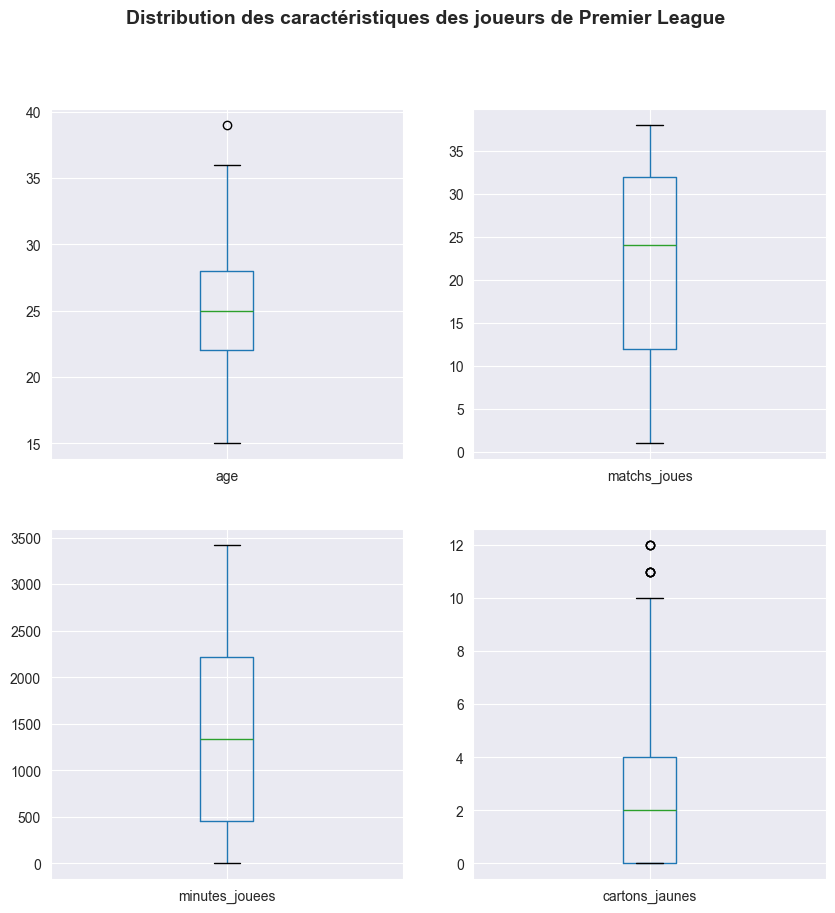

In [38]:
fig,axes=plt.subplots(nrows=2,ncols=2,figsize=(10, 10))

df_stat_premier_league.boxplot(column="age",ax=axes[0,0])

df_stat_premier_league.boxplot(column="matchs_joues",ax=axes[0,1])

df_stat_premier_league.boxplot(column="minutes_jouees",ax=axes[1,0])

df_stat_premier_league.boxplot(column="cartons_jaunes",ax=axes[1,1])

fig.suptitle("Distribution des caractéristiques des joueurs de Premier League",fontsize=14,fontweight="bold")


Text(0.5, 0.98, 'Distribution des caractéristiques des joueurs de Premier League')

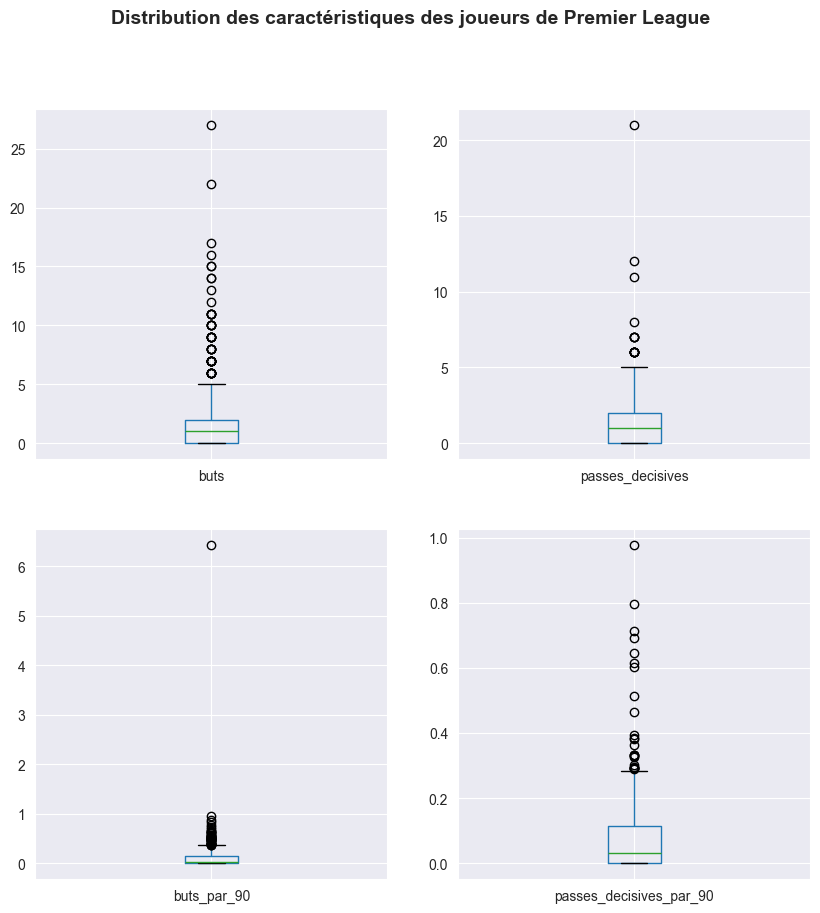

In [39]:
fig,axes=plt.subplots(nrows=2,ncols=2,figsize=(10, 10))

df_stat_premier_league.boxplot(column="buts",ax=axes[0,0])
df_stat_premier_league.boxplot(column="passes_decisives",ax=axes[0,1])
df_stat_premier_league.boxplot(column="buts_par_90",ax=axes[1,0])
df_stat_premier_league.boxplot(column="passes_decisives_par_90",ax=axes[1,1])
fig.suptitle("Distribution des caractéristiques des joueurs de Premier League",fontsize=14,fontweight="bold")

Text(0.5, 0.98, 'Distribution de la valeur marchande  des joueurs de Premier League')

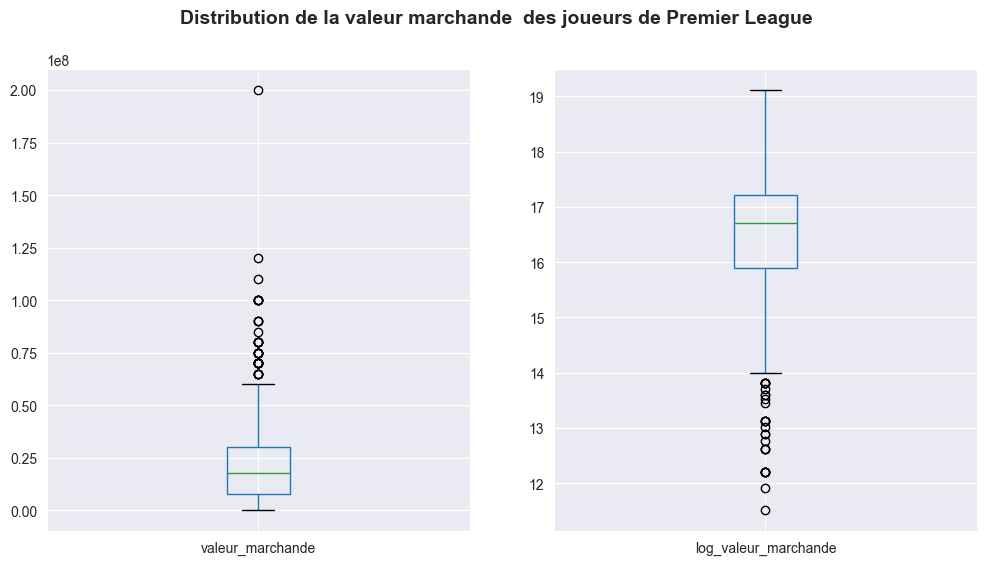

In [40]:
fig,axes=plt.subplots(nrows=1,ncols=2,figsize=(12, 6))

df_stat_premier_league.boxplot(column="valeur_marchande",ax=axes[0])
df_stat_premier_league.boxplot(column="log_valeur_marchande",ax=axes[1])
fig.suptitle("Distribution de la valeur marchande  des joueurs de Premier League",fontsize=14,fontweight="bold")

Les boxplots permettent de mettre en lumière certaines caractéristiques que les statistiques descriptives avaient déjà soulignées.
- L'échantillon est en moyenne jeune, même s'il y a certains joueurs âgés.
- Les performances comme les buts et les passes décisives sont plutôt faibles, cela peut s'expliquer par la différence de poste, un défenseur va marquer moins de buts qu'un attaquant.
- La distribution de la valeur marchande est très grande contrairement à celle de la log(valeur_marchande), donc on préférera cette dernière pour effectuer une régression.

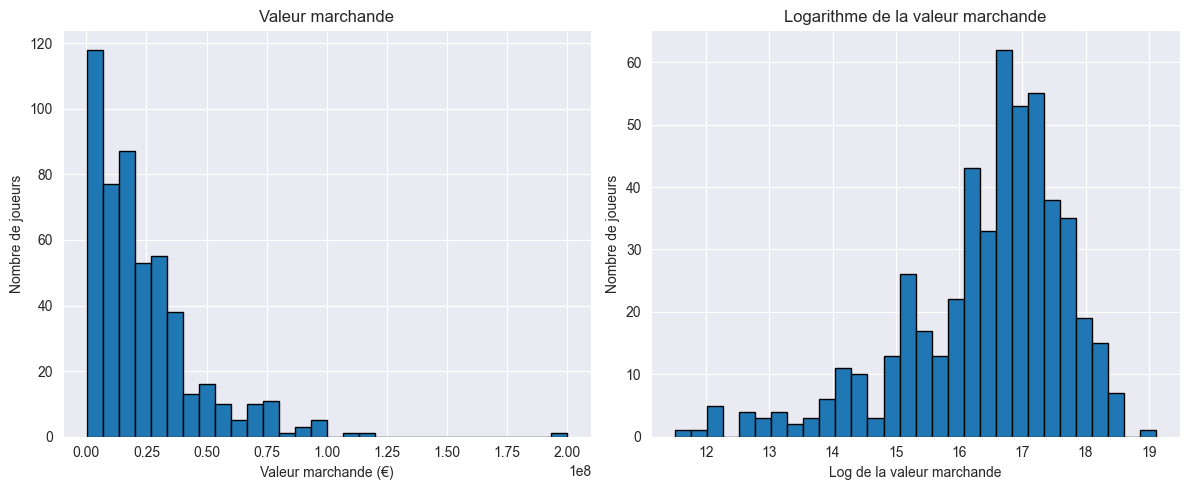

In [41]:
fig,axes=plt.subplots(nrows=1,ncols=2,figsize=(12, 5))

df_stat_premier_league['valeur_marchande'].hist(bins=30,ax=axes[0],edgecolor='black')
axes[0].set_title("Valeur marchande")
axes[0].set_xlabel("Valeur marchande (€)")
axes[0].set_ylabel("Nombre de joueurs")

df_stat_premier_league['log_valeur_marchande'].hist(bins=30,ax=axes[1],edgecolor='black')
axes[1].set_title("Logarithme de la valeur marchande")
axes[1].set_xlabel("Log de la valeur marchande")
axes[1].set_ylabel("Nombre de joueurs")

plt.tight_layout()
plt.show()

L'histogramme confirme encore nos intuitions :
- **Valeur marchande** : La distribution est fortement asymétrique vers la droite. La majorité des joueurs ont une valeur marchande relativement faible, tandis qu'un petit nombre de joueurs possède une valeur très élevée, pouvant atteindre 200 millions d'euros. Ces valeurs extrêmes tirent la moyenne vers le haut.

- **Logarithme de la valeur marchande** : Après la transformation logarithmique, la distribution devient plus symétrique et se rapproche d'une distribution normale (en forme de cloche), même si une légère asymétrie vers la gauche persiste.

- **Conclusion** : La transformation logarithmique permet de réduire l'asymétrie et l'influence des valeurs extrêmes. Il semble donc plus pertinent d'utiliser `log_valeur_marchande` plutôt que `valeur_marchande` comme variable à expliquer dans notre modèle de régression linéaire.

#### <span style="color: red">Variables catégorielles</span>

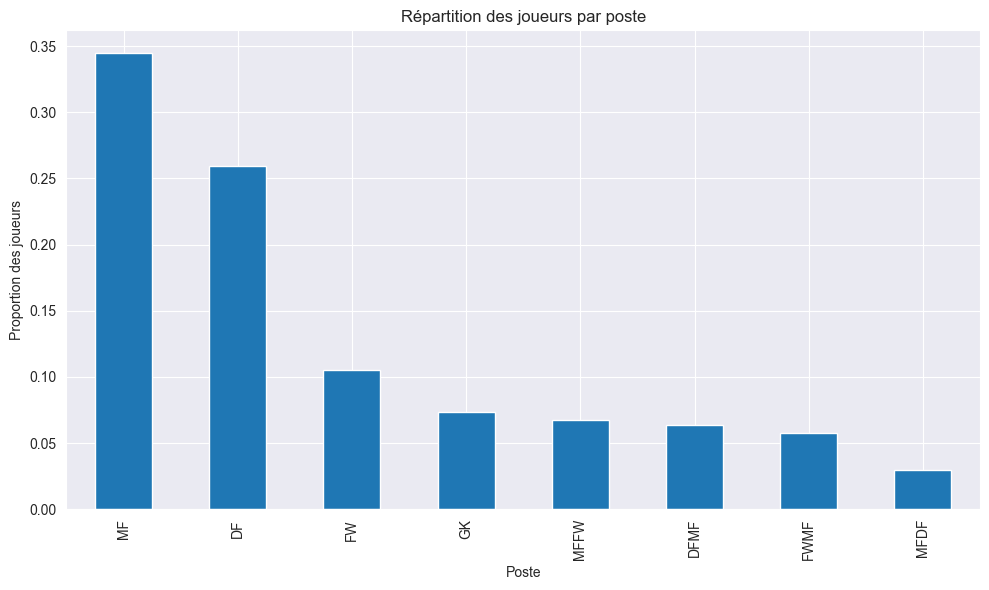

In [42]:
fig,ax=plt.subplots(nrows=1,ncols=1,figsize=(10, 6))

df_stat_premier_league['poste'].value_counts(normalize=True).plot(kind='bar',ax=ax)

ax.set_title("Répartition des joueurs par poste")
ax.set_xlabel("Poste")
ax.set_ylabel("Proportion des joueurs")

plt.tight_layout()
plt.show()

Le diagramme en bâtons permet de visualiser les différentes modalités des variables catégorielles ainsi que leur répartition dans l'échantillon :
- La majorité des joueurs (35 %) sont des milieux.
- Puis des défenseurs (26 %) et des attaquants (10 %).
- Il y a des joueurs qui peuvent jouer à plusieurs postes, environ 6 % par combinaison de postes.

Remarque : On ne trace pas l'histogramme des nationalités, car il y a trop de modalités, ce qui rend l'histogramme illisible.

### <span style="color:red">Statistiques bivariées</span>

Les statistiques bivariées permettent de comprendre la structure des données, c'est-à-dire comment les différentes variables interagissent entre elles. Dans notre cas, nous sommes particulièrement intéressés de voir comment la variable à expliquer (`log_valeur_marchande`) est corrélée aux différentes variables à notre disposition. Cette étape doit permettre de **définir les variables pertinentes à inclure dans notre régression**.

#### <span style="color:red">Valeur marchande selon l'age</span>

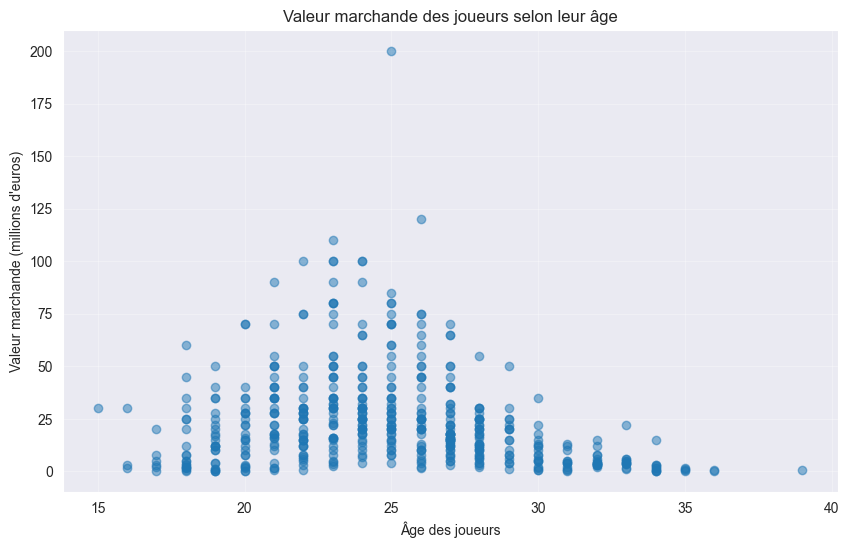

In [43]:
plt.figure(figsize=(10,6))

plt.scatter(df_stat_premier_league["age"],df_stat_premier_league["valeur_marchande"]/1_000_000,alpha=0.5)

plt.xlabel("Âge des joueurs")
plt.ylabel("Valeur marchande (millions d'euros)")
plt.title("Valeur marchande des joueurs selon leur âge")
plt.grid(alpha=0.3)

plt.show()

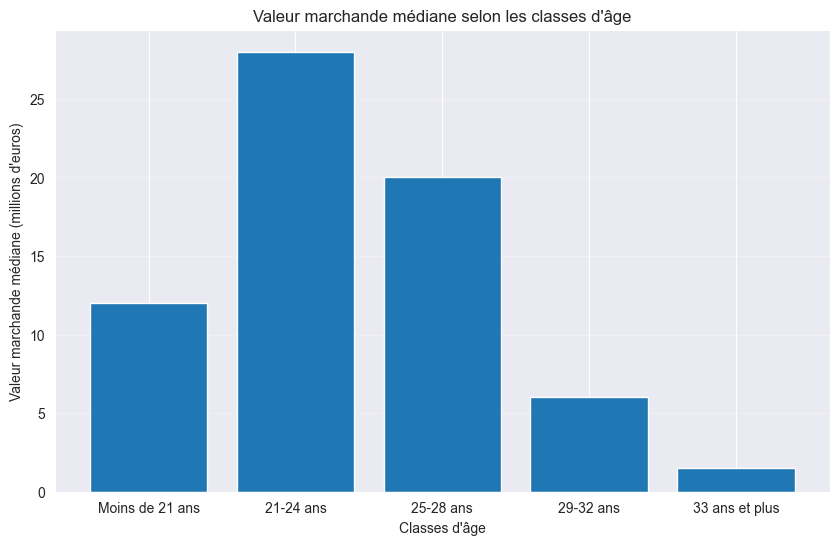

In [44]:
#Création des classes d'âge
bins=[0,20,24,28,32,100]
labels=["Moins de 21 ans","21-24 ans","25-28 ans","29-32 ans","33 ans et plus"]

df_stat_premier_league["classe_age"]=pd.cut(df_stat_premier_league["age"],bins=bins,labels=labels)

valeur_mediane=(df_stat_premier_league.groupby("classe_age",observed=True)["valeur_marchande"].median()/1_000_000)

plt.figure(figsize=(10,6))

plt.bar(valeur_mediane.index,valeur_mediane.values)

plt.xlabel("Classes d'âge")
plt.ylabel("Valeur marchande médiane (millions d'euros)")
plt.title("Valeur marchande médiane selon les classes d'âge")
plt.grid(axis="y",alpha=0.3)

plt.show()

Les deux graphiques nous permettent d'établir plusieurs premiers constats :

- Le nuage de points montre une relation potentiellement non linéaire entre l'âge des joueurs et leur valeur marchande. Au début de la distribution, une augmentation de l'âge (jusqu'à environ 23 ans) semble s'accompagner d'une hausse de la valeur marchande, ce qui pourrait notamment s'expliquer par une augmentation de l'expérience. Au-delà de cet âge, cette relation semble s'atténuer. Cela nous donne donc une première intuition concernant les variables explicatives à intégrer dans notre futur modèle économétrique : l'âge et son carré.

- Nous pouvons compléter cette intuition avec le diagramme en barres, qui montre que les joueurs ayant la valeur marchande médiane la plus élevée se situent dans la tranche des 21-24 ans.

- Nous soulignons également la forte dispersion des valeurs marchandes entre les joueurs ayant le même âge. Cela suggère que d'autres facteurs interviennent dans la valorisation des joueurs.

- Enfin, nous remarquons une fois de plus que certaines valeurs marchandes sont particulièrement élevées, ce qui renforce l'intérêt de considérer le logarithme de la valeur marchande dans notre future analyse économétrique.

#### <span style="color:red">Valeur marchande selon le poste</span>

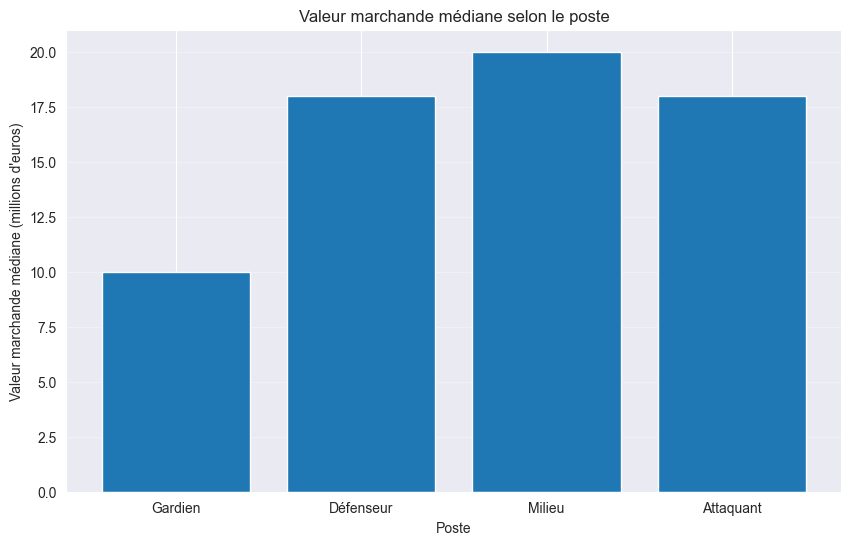

In [45]:
correspondance={"GK":"Gardien","DF":"Défenseur","MF":"Milieu","FW":"Attaquant"}

df_stat_premier_league["poste_regroupe"]=(df_stat_premier_league["poste"].str[:2].map(correspondance))

ordre_postes=["Gardien","Défenseur","Milieu","Attaquant"]

valeur_mediane_poste=(
    df_stat_premier_league
    .groupby("poste_regroupe")["valeur_marchande"]
    .median()
    .reindex(ordre_postes) / 1_000_000
)

plt.figure(figsize=(10, 6))

plt.bar(valeur_mediane_poste.index,valeur_mediane_poste.values)

plt.xlabel("Poste")
plt.ylabel("Valeur marchande médiane (millions d'euros)")
plt.title("Valeur marchande médiane selon le poste")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [46]:
df_stat_premier_league["poste_regroupe"].value_counts(dropna=False)

poste_regroupe
Milieu       223
Défenseur    163
Attaquant     82
Gardien       37
Name: count, dtype: int64



Le graphique représentant la valeur marchande médiane selon le poste nous permet d'établir plusieurs constats.

Tout d'abord, nous observons que les milieux possèdent la valeur marchande médiane la plus élevée, avec 20 millions d'euros. Ils sont suivis par les défenseurs et les attaquants, dont les valeurs marchandes médianes sont identiques, à 18 millions d'euros.

En revanche, les gardiens présentent une valeur marchande médiane nettement inférieure, de 10 millions d'euros. Leur valeur médiane est donc deux fois plus faible que celle des milieux.

Ces résultats suggèrent qu'il existe des différences de valorisation selon le poste occupé par les joueurs. Cependant, les écarts entre les trois catégories de joueurs de champ restent relativement faibles.

Cela nous donne une première intuition concernant l'intérêt d'intégrer le poste comme variable explicative dans notre futur modèle économétrique. Il sera notamment intéressant de déterminer si ces différences persistent lorsque nous contrôlons les autres caractéristiques des joueurs, comme leur âge et leurs performances.

#### <span style="color:red">Valeur marchande et performance</span>

À présent, nous allons étudier la relation entre la valeur marchande et les performances des joueurs, à savoir leur nombre de buts, de passes décisives et de minutes jouées.

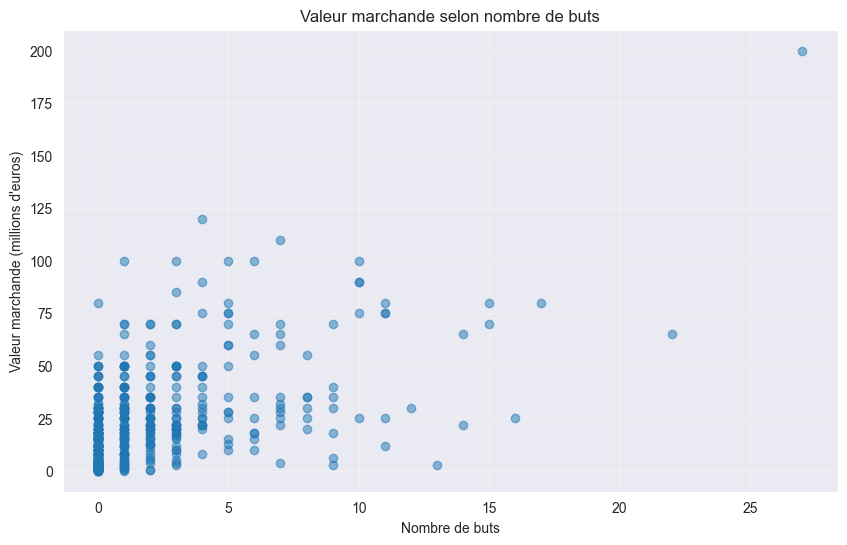

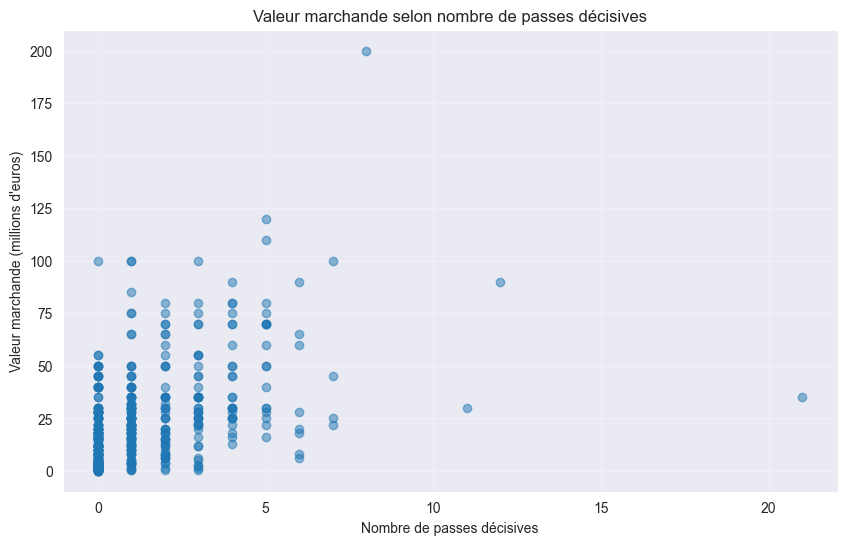

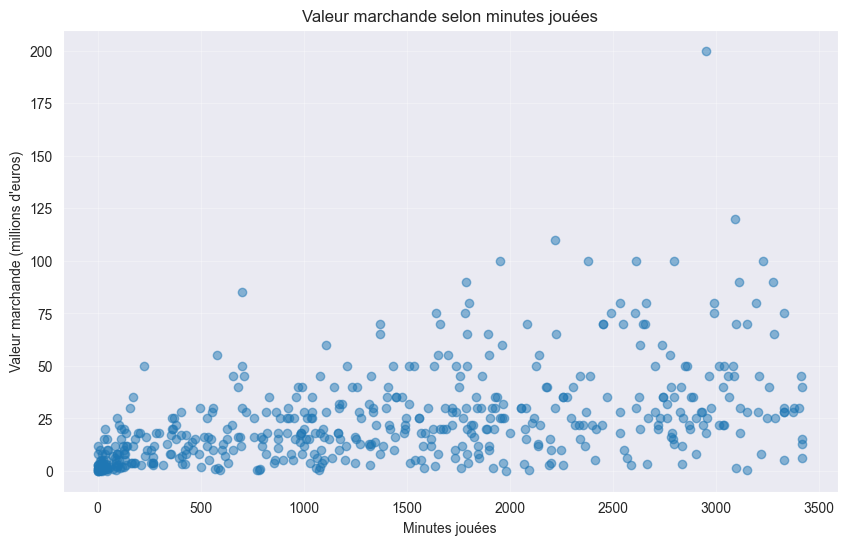

In [47]:
variables={"buts":"Nombre de buts","passes_decisives":"Nombre de passes décisives","minutes_jouees":"Minutes jouées"}

for colonne, label in variables.items():
    plt.figure(figsize=(10, 6))
    plt.scatter(df_stat_premier_league[colonne],df_stat_premier_league["valeur_marchande"]/1_000_000,alpha=0.5)

    plt.xlabel(label)
    plt.ylabel("Valeur marchande (millions d'euros)")
    plt.title(f"Valeur marchande selon {label.lower()}")
    plt.grid(alpha=0.3)

    plt.show()

Les trois graphiques nous permettent d'établir plusieurs constats concernant la relation entre les performances sportives des joueurs et leur valeur marchande.

Tout d'abord, nous observons une relation globalement positive entre le nombre de buts marqués et la valeur marchande. Les joueurs ayant marqué davantage de buts semblent généralement mieux valorisés. Cependant, nous remarquons une forte dispersion, notamment chez les joueurs ayant marqué peu de buts.

Nous retrouvons un constat similaire concernant les passes décisives. Les joueurs réalisant davantage de passes décisives semblent généralement posséder une valeur marchande plus élevée, même si cette relation reste assez dispersée.

Enfin, le nombre de minutes jouées semble également présenter une relation positive avec la valeur marchande. Les joueurs ayant disputé davantage de minutes tendent à être mieux valorisés, bien que des différences importantes subsistent entre les joueurs.

Ces observations nous donnent de premières intuitions concernant l'intérêt d'intégrer les buts, les passes décisives et les minutes jouées comme variables explicatives dans notre futur modèle économétrique. Cependant, les graphiques ne permettent pas de déterminer si ces relations persistent lorsque nous contrôlons les autres caractéristiques des joueurs.

#### <span style="color:red">Analyse des corrélations</span>


### <span style="color:red">Analyse des corrélations</span>

In [48]:
df_stat_premier_league.corr(numeric_only=True)["log_valeur_marchande"].sort_values(ascending=False)

log_valeur_marchande                    1.000000
valeur_marchande                        0.772442
matchs_joues                            0.560569
minutes_jouees                          0.508666
equivalent_90_minutes                   0.508666
titularisations                         0.502787
buts_plus_passes                        0.439860
buts_hors_penalty                       0.387052
buts                                    0.378001
passes_decisives                        0.377107
cartons_jaunes                          0.328436
annee_naissance                         0.264828
passes_decisives_par_90                 0.240970
penaltys_tentes                         0.154066
penaltys_marques                        0.153421
buts_plus_passes_par_90                 0.089089
buts_plus_passes_hors_penalty_par_90    0.080280
cartons_rouges                          0.073765
buts_par_90                             0.008780
buts_hors_penalty_par_90               -0.001720
age                 

L'analyse des corrélations permet d'identifier plusieurs variables présentant une association linéaire avec le logarithme de la valeur marchande.

Tout d'abord, les variables liées au temps de jeu présentent les corrélations positives les plus élevées. Les matchs joués (0,561), les minutes jouées (0,509) et les titularisations (0,503) semblent donc particulièrement associés à la valeur marchande des joueurs.

Ensuite, nous observons des corrélations positives modérées concernant les performances offensives, notamment les buts (0,378), les passes décisives (0,377) et leur somme (0,440).

Concernant l'âge, nous obtenons une corrélation négative de -0,262. Cependant, comme nous l'avons observé précédemment, la relation entre l'âge et la valeur marchande pourrait être non linéaire, ce qui justifierait l'introduction de l'âge au carré dans notre futur modèle économétrique.

Enfin, nous remarquons que certaines statistiques par 90 minutes présentent des corrélations très faibles avec la valeur marchande, notamment les buts par 90 minutes (0,009). Ce résultat devra être interprété avec prudence, car ces statistiques peuvent être influencées par le poste et le temps de jeu des joueurs.

Ces premières observations nous permettent d'identifier plusieurs variables potentiellement pertinentes pour notre future modélisation. Toutefois, les corrélations ne permettent pas de déterminer si ces associations persistent lorsque les autres caractéristiques des joueurs sont prises en compte.

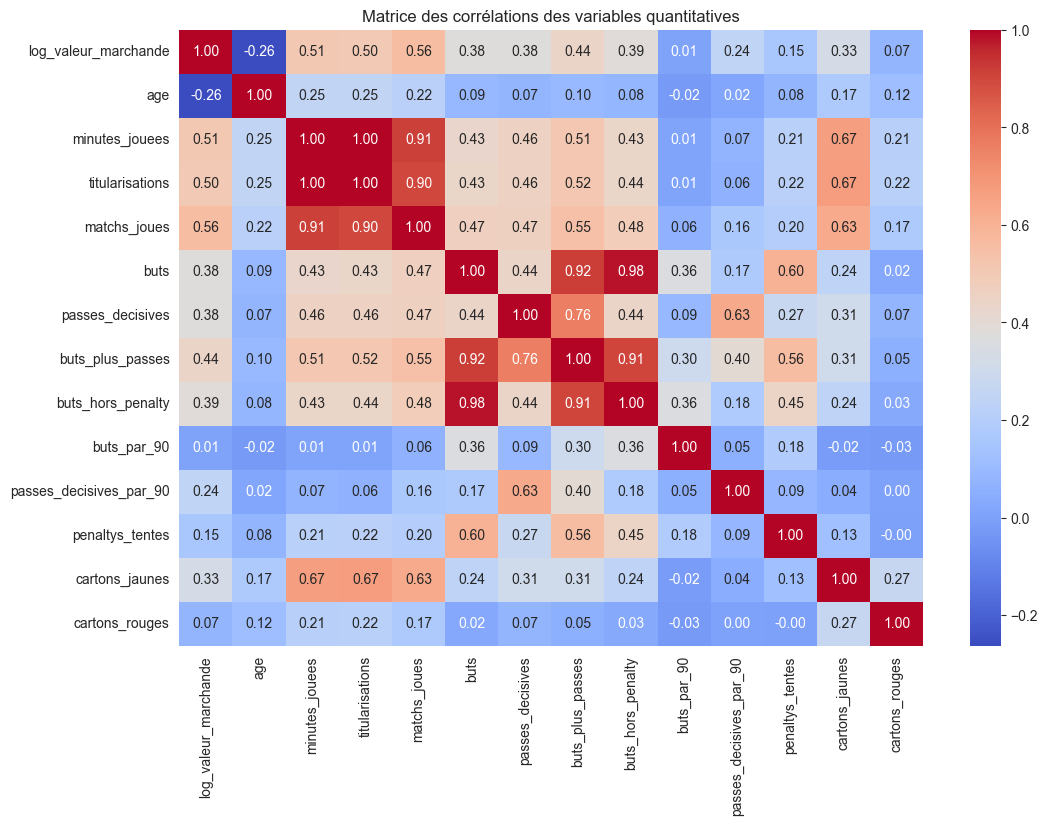

In [50]:
#Variables quantitatives à étudier pour la future régression
variables_corr=[
    "log_valeur_marchande",
    "age",
    "minutes_jouees",
    "titularisations",
    "matchs_joues",
    "buts",
    "passes_decisives",
    "buts_plus_passes",
    "buts_hors_penalty",
    "buts_par_90",
    "passes_decisives_par_90",
    "penaltys_tentes",
    "cartons_jaunes",
    "cartons_rouges"
]

matrice_corr=df_stat_premier_league[variables_corr].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(matrice_corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Matrice des corrélations des variables quantitatives")
plt.show()

La matrice de corrélation met en évidence plusieurs groupes de variables fortement corrélées entre elles.

Tout d'abord, les minutes jouées, les titularisations et les matchs joués présentent des corrélations particulièrement élevées, comprises entre 0,90 et 1. Ces trois variables apportent donc des informations relativement similaires concernant le temps de jeu des joueurs. Pour notre premier modèle économétrique, nous privilégierons les minutes jouées.

Ensuite, nous observons de fortes corrélations entre les différentes variables mesurant les performances offensives, notamment les buts, les buts hors penalty et la somme des buts et des passes décisives. Nous privilégierons les buts et les passes décisives séparément afin de pouvoir étudier leurs associations respectives avec la valeur marchande.

Enfin, cette analyse nous aide à sélectionner un premier ensemble de variables explicatives : l'âge, son carré, les minutes jouées, les buts, les passes décisives et le poste du joueur.

Il faudra toutefois compléter ces observations par des diagnostics économétriques, notamment pour vérifier les éventuels problèmes de multicolinéarité. Le choix définitif des variables dépendra également de leur pertinence économique et des résultats des régressions.

## <span style="color:RED">Conclusion</span>

Cette analyse descriptive nous a permis d'établir de premiers constats et d'identifier plusieurs variables potentiellement pertinentes pour expliquer la valeur marchande des joueurs de Premier League, notamment l'âge, le temps de jeu et les performances offensives.

Afin d'approfondir ces observations, **nous réaliserons dans le prochain notebook une analyse économétrique** pour mesurer les relations entre ces variables et la valeur marchande des joueurs, puis effectuer différents tests statistiques pour évaluer la pertinence de nos résultats.